# EDA: Legal Corpus (YuITC/Vietnamese-Legal-Documents)

This notebook performs Exploratory Data Analysis (EDA) on the `corpus.parquet` file. The goal is to understand the structure, data quality, document lengths, and legal characteristics of the corpus before applying any preprocessing or retrieval mechanisms.

## Table of Contents
1. Load Data
2. ID Integrity
3. Text Availability
4. Document Length Distribution
5. Inspect Extreme Documents
6. Duplicate Analysis
7. Legal Structure Analysis
8. EDA Conclusions

In [ ]:
import pandas as pd
import numpy as np
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Adjust pandas display options for better inspection
pd.set_option('display.max_colwidth', 500)
pd.set_option('display.max_rows', 100)

# Set visualization style
sns.set_theme(style="whitegrid")
sys.path.append('../')
from src.data.data_loader import load_parquet_data
corpus = load_parquet_data("../data/raw/YuITC/corpus.parquet") 


## Section 1 — Load Data
Analyze the fundamental properties of the dataset: size, columns, data types, and memory footprint.

In [2]:
print(f"Corpus shape: {corpus.shape}")
print("\n--- Data Types & Memory Usage ---")
corpus.info(memory_usage='deep')

print("\n--- First 5 Rows ---") 
display(corpus.head())

Corpus shape: (261597, 2)

--- Data Types & Memory Usage ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261597 entries, 0 to 261596
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    261597 non-null  object
 1   cid     261597 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 561.7 MB

--- First 5 Rows ---


,text,cid
0,"Thông tư này hướng dẫn tuần tra, canh gác bảo vệ đê Điều trong mùa lũ đối với các tuyến đê sông được phân loại, phân cấp theo quy định tại Điều 4 của Luật Đê Điều.",0
1,"1. Hàng năm trước mùa mưa, lũ, Ủy ban nhân dân cấp xã nơi có đê phải tổ chức lực lượng lao động tại địa phương để tuần tra, canh gác đê và thường trực trên các điếm canh đê hoặc nhà dân khu vực gần đê (đối với những khu vực chưa có điếm canh đê), khi có báo động lũ từ cấp I trở lên đối với tuyến sông có đê (sau đây gọi tắt là lực lượng tuần tra, canh gác đê).\n2. Lực lượng tuần tra, canh gác đê được tổ chức thành các đội, do Ủy ban nhân dân cấp xã ra quyết định thành lập; từ 01 đến 02 kilômé...",1
2,"Tiêu chuẩn của các thành viên thuộc lực lượng tuần tra, canh gác đê\n1. Là người khoẻ mạnh, tháo vát, đủ khả năng đảm đương những công việc nặng nhọc, kể cả lúc mưa to, gió lớn, đêm tối.\n2. Có tinh thần trách nhiệm, chịu đựng gian khổ, khắc phục khó khăn, quen sông nước và biết bơi, có kiến thức, kinh nghiệm hộ đê, phòng, chống lụt, bão.",2
3,"Nhiệm vụ của lực lượng tuần tra, canh gác đê\n1. Chấp hành sự phân công của Ban chỉ huy phòng, chống lụt, bão các cấp và chịu sự hướng dẫn về chuyên môn nghiệp vụ của cơ quan chuyên trách quản lý đê Điều.\n2. Tuần tra, canh gác và thường trực trên các điếm canh đê, khi có báo động lũ từ cấp I trở lên đối với tuyến sông có đê. Theo dõi diễn biến của đê Điều; phát hiện kịp thời những hư hỏng của đê Điều và báo cáo ngay cho Ban chỉ huy chống lụt bão xã, cán bộ chuyên trách quản lý đê Điều phụ t...",3
4,"Phù hiệu của lực lượng tuần tra, canh gác đê\nPhù hiệu của lực lượng tuần tra, canh gác đê là một băng đỏ rộng 10cm, có ký hiệu “KTĐ” màu vàng.\nPhù hiệu được đeo trên khuỷu tay áo bên trái, chữ “KTĐ” hướng ra phía ngoài.",4


## Section 2 — ID Integrity
Ensure that the document identifier (`cid`) is unique, completely populated, and acts as a proper primary key for retrieval.

In [3]:
total_rows = len(corpus)
unique_cids = corpus['cid'].nunique()
missing_cids = corpus['cid'].isna().sum()
duplicate_cids = total_rows - unique_cids

print(f"Total rows: {total_rows}")
print(f"Unique CIDs: {unique_cids}")
print(f"Missing CIDs (Nulls): {missing_cids}")
print(f"Duplicate CIDs: {duplicate_cids}")

if duplicate_cids > 0:
    print("\n--- Sample of Duplicate CIDs ---")
    display(corpus[corpus.duplicated(subset=['cid'], keep=False)].sort_values('cid').head(10)) 

Total rows: 261597
Unique CIDs: 261597
Missing CIDs (Nulls): 0
Duplicate CIDs: 0


## Section 3 — Text Availability
Check for missing, empty, whitespace-only, or extremely short text entries. We also initialize the `word_count` and `char_count` features for downstream analysis.

In [ ]:
# 1. Null text
null_text_count = corpus['text'].isna().sum()

# 2. Empty text (exactly "")
empty_text_count = (corpus['text'] == "").sum()

# 3. Whitespace-only text (contains only spaces, tabs, newlines)
# Fillna with empty string to avoid errors on nulls
corpus['text'] = corpus['text'].fillna("")
whitespace_only_count = corpus['text'].str.isspace().sum()

print(f"Null texts: {null_text_count}")
print(f"Empty texts (''): {empty_text_count}")
print(f"Whitespace-only texts: {whitespace_only_count}")

# Feature Engineering: Lengths
corpus['word_count'] = corpus['text'].str.split().str.len()
corpus['char_count'] = corpus['text'].str.len()

# 4. Extremely short text (e.g., less than 5 words) 
short_text_count = (corpus['word_count'] < 5).sum()
print(f"Extremely short texts (< 5 words): {short_text_count}")

Null texts: 0
Empty texts (''): 0
Whitespace-only texts: 0
Extremely short texts (< 5 words): 34


## Section 4 — Document Length Distribution
Analyze how long the documents in the corpus are. This directly dictates our **chunking and retrieval strategy**. If documents are extremely long, we must split them into passages. If they are already passage-sized, we might not need to chunk.

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
word_count,261597.0,240.138266,297.361953,1.0,96.0,175.0,307.0,529.0,626.0,896.04,55368.0
char_count,261597.0,1088.734917,1341.555501,4.0,436.0,793.0,1393.0,2405.0,2829.0,4047.00,252881.0


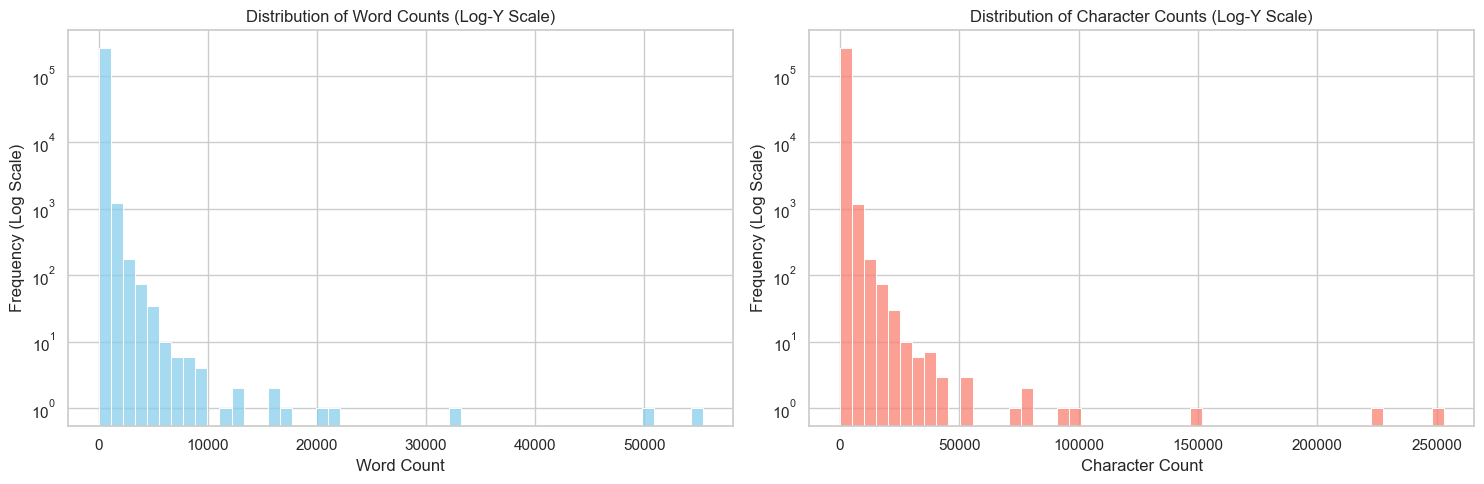

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tính toán các bách phân vị quan trọng
percentiles = [.25, .50, .75, .90, .95, .99]
length_stats = corpus[["word_count", "char_count"]].describe(percentiles=percentiles).T
display(length_stats)

# Vẽ biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ Word Count (Dùng set_yscale('log') để an toàn cho mọi version matplotlib/seaborn)
sns.histplot(corpus["word_count"], bins=50, ax=axes[0], color="skyblue")
axes[0].set_yscale("log")
axes[0].set_title("Distribution of Word Counts (Log-Y Scale)")
axes[0].set_xlabel("Word Count") 
axes[0].set_ylabel("Frequency (Log Scale)")

# Biểu đồ Character Count
sns.histplot(corpus["char_count"], bins=50, ax=axes[1], color="salmon")
axes[1].set_yscale("log")
axes[1].set_title("Distribution of Character Counts (Log-Y Scale)")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("Frequency (Log Scale)")

plt.tight_layout()
plt.show()

## Section 5 — Inspect Extreme Documents
Do not just look at statistics. We must visually inspect the shortest, longest, and random documents to understand the actual content structure.

In [ ]:
print("--- 10 Shortest Documents ---")
display(corpus.nsmallest(10, "word_count")[["cid", "word_count", "text"]])

print("\n--- 10 Longest Documents ---")
display(corpus.nlargest(10, "word_count")[["cid", "word_count", "text"]])

print("\n--- 20 Random Documents ---")
# random_state=42 giúp bạn chạy lại nhiều lần vẫn ra đúng 20 văn bản này 
display(corpus.sample(20, random_state=42)[["cid", "word_count", "text"]]) 

--- 10 Shortest Documents ---


,cid,word_count,text
59775,68818,1,....
105342,181817,2,...\n\n....
109288,194853,2,....\n...
115482,216011,2,...\n...
119292,229433,2,...\n...
126252,256577,2,...\n...
218580,578502,2,Đại diện.........................................................................................................................
79099,108219,3,"1. Nhà, đất."
21122,23264,4,1. Đạt tiêu chuẩn:
131594,446864,4,Khoản 1.3. Nhận xét:



--- 10 Longest Documents ---


,cid,word_count,text
15843,17161,55368,"1. Sửa đổi, bổ sung Điều 3 như sau:\na) Sửa đổi, bổ sung điểm d khoản 1 Điều 3 như sau:\n“d) Nghiêm trị người phạm tội dùng thủ đoạn xảo quyệt, có tổ chức, có tính chất chuyên nghiệp, cố ý gây hậu quả đặc biệt nghiêm trọng.\nKhoan hồng đối với người tự thú, đầu thú, thành khẩn khai báo, tố giác đồng phạm, lập công chuộc tội, tích cực hợp tác với cơ quan có trách nhiệm trong việc phát hiện tội phạm hoặc trong quá trình giải quyết vụ án, ăn năn hối cải, tự nguyện sửa chữa hoặc bồi thường thiệt..."
25326,27908,50664,"1. Tài khoản 111 - Tiền mặt\nTài khoản này dùng để phản ánh tình hình thu, chi, tồn tiền mặt tại quỹ của BQLDAĐT, bao gồm: Tiền Việt Nam, ngoại tệ.\n1.1. Nguyên tắc hạch toán\n- Chỉ phản ánh vào Tài khoản 111 “Tiền mặt” số tiền mặt, ngoại tệ thực tế nhập, xuất quỹ tiền mặt. Đối với những khoản tiền thu được chuyển nộp ngay vào Ngân hàng, Kho bạc Nhà nước (không qua quỹ tiền mặt của đơn vị) thì không ghi vào bên Nợ Tài khoản 111 “Tiền mặt” mà ghi vào bên Nợ Tài khoản 113 “Tiền đang chuyển”.\n..."
22674,24965,32667,"1. Sửa đổi, bổ sung điểm 1 như sau:\na) Sửa đổi, bổ sung điểm 1.1 như sau:\n“1.1 Các quyền sở hữu công nghiệp phát sinh hoặc được xác lập dựa trên các căn cứ quy định tại khoản 3 Điều 6 của Luật Sở hữu trí tuệ, các khoản 1, 2, 3 và 4 Điều 6 của Nghị định số 103/2006/NĐ-CP ngày 22/9/2006 của Chính phủ quy định chi tiết và hướng dẫn thi hành một số điều của Luật Sở hữu trí tuệ về sở hữu công nghiệp, được sửa đổi, bổ sung theo Nghị định số 122/2010/NĐ-CP (sau đây gọi là “Nghị định số 103/2006/N..."
45312,50363,22006,"1. Bổ sung Khoản 6, Khoản 7 Điều 3 như sau:\n“6. “Kiểm tra chuyên ngành” là việc cơ quan kiểm tra chuyên ngành căn cứ các quy định về kiểm dịch thực vật, kiểm dịch động vật, tiêu chuẩn quốc gia, quy chuẩn kỹ thuật quốc gia về chất lượng hàng hóa do các cơ quan quản lý nhà nước ban hành hoặc tiêu chuẩn quốc tế hoặc các quy định pháp luật có liên quan để kiểm tra, xác định hàng hóa đủ điều kiện xuất khẩu, nhập khẩu theo quy định của pháp luật có liên quan.\nHàng hóa xuất khẩu, nhập khẩu kiểm t..."
25319,27900,20966,"1. Tài khoản 133 - Thuế GTGT được khấu trừ\nTài khoản này dùng để phản ánh số thuế GTGT đầu vào phát sinh trong quá trình đầu tư xây dựng được khấu trừ, đã khấu trừ và còn được khấu trừ của BQLDAĐT.\n1.1. Nguyên tắc hạch toán\n- Tài khoản 133 chỉ áp dụng đối với các BQLDAĐT nộp thuế GTGT theo phương pháp khấu trừ thuế và quá trình đầu tư tạo ra TSCĐ dùng cho hoạt động sản xuất kinh doanh hàng hoá, dịch vụ chịu thuế GTGT tính theo phương pháp khấu trừ.\n- Tài khoản 133 không áp dụng đối với t..."
31831,35135,17285,"1. Sửa đổi, bổ sung Điều 3 như sau:\na) Sửa đổi, bổ sung Khoản 11 như sau:\n“11. Điểm cung cấp dịch vụ trò chơi điện tử công cộng là địa điểm mà tổ chức, cá nhân được toàn quyền sử dụng hợp pháp để cung cấp cho người chơi khả năng truy nhập vào mạng và chơi trò chơi điện tử thông qua việc thiết lập hệ thống thiết bị tại địa điểm đó, bao gồm:\na) Điểm truy nhập Internet công cộng có cung cấp dịch vụ trò chơi điện tử: Đại lý Internet; điểm truy nhập Internet công cộng của doanh nghiệp cung cấp..."
35274,38956,16582,"1. Sửa đổi, bổ sung Điều 2 như sau:\n“Điều 2. Đối tượng áp dụng\n1. Luật này áp dụng đối với cơ sở giáo dục đại học, tổ chức và cá nhân có liên quan đến giáo dục đại học.\n2. Viện hàn lâm, viện do Thủ tướng Chính phủ thành lập theo quy định của Luật Khoa học và công nghệ được phép đào tạo trình độ tiến sĩ thực hiện tuyển sinh và đào tạo theo quy định của Luật này.”.\n2. Sửa đổi, bổ sung Điều 4 như sau:\n“Điều 4. Giải thích từ ngữ\nTrong Luật này, các từ ngữ dưới đây được hiểu như sau:\n1. Cơ..."
34331,37891,16410,"1. Bổ sung khoản 7, khoản 8, khoản 9 vào Điều 4\nnhư sau:\n“7. Chủ sở hữu đối với vốn nhà nước hoặc vốn của doanh nghiệp nhà nước (sau đây gọi là chủ sở hữu vốn) là cơ quan đại diện chủ sở hữu hoặc doanh nghiệp nhà nước có vốn đầu tư chuyển nhượng.\n8. Đấu giá công khai là phương thức chuyển nhượng vốn đầu tư của nhà n


--- 20 Random Documents ---


,cid,word_count,text
142278,462368,614,"Phép đo công suất phát RF phải được thực hiện ở cả điều kiện bình thường và điều kiện tới hạn của dải nhiệt độ hoạt động. Trong trường hợp thiết bị sử dụng ăng ten tích hợp mà không có đầu kết nối ăng ten mở rộng thì bộ ghép đo được mô tả trong mục B4 được sử dụng để thực hiện các phép đo tương đối tại điều kiện tới hạn của dải nhiệt độ hoạt động. Trong trường hợp thiết bị thích nghi, thiết bị phải được hoạt động theo cấu hình trong trường hợp xấu nhất đối với công suất phát RF. Trong trường..."
85177,123378,261,"Nhiệm vụ chủ yếu\n1. Về Tổ chức thương mại thế giới (WTO) và các Tổ chức quốc tế khác:\n...\nc) Giúp Bộ thực hiện đại diện lợi ích thương mại của Việt Nam, đề xuất phương án và tổ chức thực hiện các quyền và nghĩa vụ có liên quan đến kinh tế - thương mại của Việt Nam tại WTO, APEC, ASEM và tại các tổ chức, diễn đàn kinh tế quốc tế khác theo phân công của Bộ;\nd) Chủ trì hoặc phối hợp xây dựng và hướng dẫn thực hiện chính sách trong nước liên quan đến các cam kết về kinh tế - thương mại của V..."
75338,99478,438,"Nhiệm vụ của Nhà xuất bản\n1. Thực hiện các nhiệm vụ được Bộ Tài nguyên và Môi trường giao trong lĩnh vực xuất bản; in và phát hành bản đồ, sách, tài liệu chuyên ngành về tài nguyên – môi trường trong phạm vi cả nước;\n2. Xuất bản các văn bản hướng dẫn thi hành pháp luật, sách, tài liệu chuyên ngành phục vụ công tác quản lý, phổ biến pháp luật, khoa học – kỹ thuật, thông tin, tuyên truyền về tài nguyên, môi trường;\n3. Xuất bản, in và phát hành hệ thống bản đồ địa chính, địa chính, hành chín..."
140619,460087,104,"Điều 6. Hình thức thanh tra\n1. Việc tổ chức thanh tra an toàn địa điểm nhà máy điện hạt nhân được thực hiện theo kế hoạch, thanh tra thường xuyên hoặc thanh tra đột xuất quy định tại Điều 37 Luật Thanh tra.\n2. Việc tổ chức thanh tra an toàn địa điểm nhà máy điện hạt nhân được tiến hành do đoàn thanh tra hoặc do thanh tra viên, người được giao nhiệm vụ thực hiện thanh tra chuyên ngành tiến hành độc lập theo quyết định thanh tra của người có thẩm quyền quy định tại Điều 51 Luật Thanh tra."
137200,455161,143,"Điều 16. Công bố nội dung Giấy phép kinh doanh vận chuyển hàng không, Giấy phép kinh doanh hàng không chung vì mục đích thương mại\n1. Trong thời hạn 30 ngày làm việc, kể từ ngày được cấp Giấy phép kinh doanh vận chuyển hàng không, Giấy phép kinh doanh hàng không chung vì mục đích thương mại, hãng hàng không phải đăng trên một trong các tờ báo viết Trung ương hoặc báo điện tử trong ba số liên tiếp các nội dung của Giấy phép.\n2. Trong trường hợp, nội dung Giấy phép kinh doanh vận chuyển hàng..."
235902,606037,302,"Điều 5. Trường hợp miễn, giảm phí\n1. Các trường hợp được miễn phí bao gồm:\na) Đại biểu, khách mời của cơ quan Đảng, Nhà nước, Quốc hội, Chính phủ.\nb) Trẻ em, học sinh các trường tiểu học, trung học cơ sở, trung học phổ thông. Học sinh là người có học sinh do các nhà trường thuộc hệ thống giáo dục quốc dân ở Việt Nam cấp.\nc) Người khuyết tật đặc biệt nặng theo quy định tại khoản 1 Điều 11 Nghị định số 28/2012/NĐ-CP ngày 10 tháng 4 năm 2012 của Bộ Tài chính quy định chi tiết, hướng dẫn thi..."
174108,509960,169,"Khoản 3. Thông tin về công dân được cơ quan quản lý Cơ sở dữ liệu quốc gia về dân cư thu thập, cập nhật vào cơ sở dữ liệu như sau:\na) Thông tin về công dân được thu thập, cập nhật từ sổ sách quản lý về cư trú, tàng thư hồ sơ hộ khẩu, tàng thư căn cước công dân, Cơ sở dữ liệu về cư trú, Cơ sở dữ liệu căn cước công dân;\nb) Trường hợp sổ sách quản lý về cư trú, tàng thư và các cơ sở dữ liệu quy định tại Điểm a Khoản này chưa có hoặc chưa đầy đủ thì thu thập, cập nhật từ Cơ sở dữ liệu hộ tịch;..."
199958,549338,230,"Khoản 2. Khi thực hiện thẩm định, tổng hợp quyết toán năm của ngân sách cấp dưới, cơ quan tài chính cấp trên có quyền:\na) Yêu cầu Ủy ban nhân dân cấp xã (đối với ngân sách cấp xã), cơ quan tài chính cấp huyện (đối với ngân sách cấp huyện) bổ sung thêm những thông tin và số liệu cần thiết cho việc thẩm định quyết toán;\nb) Yêu 

## Section 6 — Duplicate Analysis
Investigate if there are duplicated contents in the corpus. Exact duplicates can skew retrieval evaluation metrics and bloat vector databases.

In [7]:
# Kiểm tra trùng lặp trên cột 'text'
exact_duplicates = corpus.duplicated(subset=["text"]).sum()

print("--- Duplicate Content Check ---")
print(f"Exact duplicated texts: {exact_duplicates:,} ({(exact_duplicates/total_rows)*100:.2f}%)")

if exact_duplicates > 0:
    # Tìm xem text nào bị trùng và trùng bao nhiêu lần
    dup_counts = corpus["text"].value_counts()
    top_dups = dup_counts[dup_counts > 1].head(5)
    
    print("\nTop 5 most frequent duplicate texts:")
    for text, count in top_dups.items():
        # Cắt chuỗi text dài quá để dễ nhìn
        print(f"\n[Appears {count} times] Snippet: {text[:150]}...")
        
    # Xem thử các CID nào đang share chung 1 đoạn text trùng lặp
    sample_dup_text = top_dups.index[0]
    shared_cids = corpus[corpus["text"] == sample_dup_text]["cid"].tolist()
    print(f"\nCIDs sharing the top duplicated text: {shared_cids[:10]}...") 

--- Duplicate Content Check ---
Exact duplicated texts: 2 (0.00%)

Top 5 most frequent duplicate texts:

[Appears 3 times] Snippet: ...
......

CIDs sharing the top duplicated text: [216011, 229433, 256577]...


## Section 7 — Legal Structure Analysis
Perform a lightweight regex check to estimate how many documents contain explicit legal terminology and hierarchical identifiers. This helps us understand if the corpus is already parsed at the article level or if it contains full laws.

In [ ]:
# Các pattern regex cơ bản để nhận diện cấu trúc luật VN
patterns = {
    "Has 'Điều' (Article)": r"(?i)\bĐiều\s+\d+",
    "Has 'Khoản' (Clause)": r"(?i)\bKhoản\s+\d+",
    "Has 'Điểm' (Point)": r"(?i)\bĐiểm\s+[a-zđ]",
    "Has 'Luật' (Law)": r"(?i)\bluật\b",
    "Has 'Nghị định' (Decree)": r"(?i)\bnghị định\b",
    "Has 'Thông tư' (Circular)": r"(?i)\bthông tư\b",
    "Has Law Number Pattern (e.g., 123/2020/NĐ-CP)": r"\d+/\d{4}/[A-ZĐ]+-[A-ZĐ]+"
}

results = []
for label, pattern in patterns.items():
    # Tìm trực tiếp trên cột 'text'
    matches = corpus["text"].str.contains(pattern, na=False)
    count = matches.sum()
    results.append({
        "Feature": label,
        "Count": count,
        "Percentage (%)": round((count / total_rows) * 100, 2)
    })

import pandas as pd
legal_structure_df = pd.DataFrame(results) 
display(legal_structure_df) 

,Feature,Count,Percentage (%)
0,Has 'Điều' (Article),111550,42.64
1,Has 'Khoản' (Clause),105426,40.30
2,Has 'Điểm' (Point),53880,20.60
3,Has 'Luật' (Law),94648,36.18
4,Has 'Nghị định' (Decree),38313,14.65
5,Has 'Thông tư' (Circular),52922,20.23
6,"Has Law Number Pattern (e.g., 123/2020/NĐ-CP)",29380,11.23


## Section 8 — EDA Conclusions

### Executive Summary

**1. Corpus Scale**
- The YuITC corpus contains **261,597 documents**, providing a substantial dataset for evaluating sparse, dense, and hybrid retrieval methods.

**2. ID Integrity**
- All `cid` values are present and unique, with **0 missing CIDs and 0 duplicate CIDs**.
- This provides a clean document identifier for retrieval evaluation and enables reliable traceability from retrieved evidence back to the original corpus entry.

**3. Missing and Extremely Short Content**
- No null or completely empty documents were detected.
- However, **34 documents contain fewer than 5 words**, with several consisting primarily of punctuation or incomplete template-like text.
- These records should be audited before preprocessing.
- Before excluding any of them, their CIDs must be checked against the gold document IDs in both the training and test sets to ensure benchmark coverage is not affected.

**4. Document Length and Retrieval Granularity**
- The median document length is **175 words**, while **95% of documents contain fewer than 626 words**.
- This indicates that most corpus entries are already relatively short and passage-like rather than extremely long full legal documents.
- Therefore, the corpus should initially be indexed at the existing **CID/document level**, without globally chunking every document before retrieval.
- This also preserves direct compatibility with the benchmark, whose relevance labels are defined using CIDs.

**5. Long-Document Outliers**
- Although most entries are short, the corpus contains extreme outliers, with a maximum length of approximately **45,536 words**.
- These outliers do not justify globally chunking the corpus.
- Instead, long retrieved documents can be handled later through a **local passage-selection stage** before being included in the LLM context.

**6. Duplicate Content**
- Only **2 exact duplicate texts** were detected, both associated with punctuation-like content.
- Exact textual duplication is therefore negligible at the corpus level.
- Global deduplication is not currently necessary.

**7. Legal Structure**
- Approximately **42.6%** of corpus entries contain the term `"Điều"` and **40.3%** contain `"Khoản"`.
- Legal references such as article numbers, clause numbers, point labels, and legal-document identifiers are therefore potentially important retrieval signals.
- Preprocessing and tokenization should preserve these identifiers rather than aggressively removing numbers, punctuation, or short legal tokens.

**8. Implications for Retrieval**
- The corpus characteristics motivate evaluating both lexical and semantic retrieval.
- BM25 may benefit from exact legal terminology and identifiers, while BGE-M3 may better handle natural-language queries and semantic mismatch.
- Their relative effectiveness must be determined experimentally rather than assumed from EDA.

**9. Implications for the RAG Pipeline**
- Initial retrieval should operate directly over the existing CID-level corpus.
- For the majority of retrieved entries, the complete text may be sufficiently short for downstream processing.
- For unusually long entries, a local passage-selection module can dynamically split and rank relevant sections before constructing the LLM context.

### Current Design Decision

Based on the corpus EDA:

Raw YuITC corpus
        ↓
Minimal text preprocessing
        ↓
CID-level indexing
        ↓
BM25 / BGE-M3 / Hybrid Retrieval
        ↓
Top retrieved CIDs
        ↓
If document is short → use directly
If document is long  → local passage selection
        ↓
RAG context